In [1]:
# ============================================================
# Step 3.1: Environment and labelled data
# ============================================================

from pathlib import Path
import json
import re

import numpy as np
import pandas as pd

from google.colab import drive


drive.mount("/content/drive")

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/"
    "Amazon-Marketplace-Product-Intelligence-Platform-BJIT"
)

PROCESSED_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
)

REPORT_DIR = (
    PROJECT_ROOT
    / "reports"
    / "price_tier"
)

MODEL_DIR = (
    PROJECT_ROOT
    / "models"
    / "price_tier"
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

LABELED_DATA_PATH = (
    PROCESSED_DIR
    / "products_price_tier_labeled.csv"
)

if not LABELED_DATA_PATH.exists():
    raise FileNotFoundError(
        "The Step 2 labelled dataset was not found:\n"
        f"{LABELED_DATA_PATH}"
    )

products = pd.read_csv(
    LABELED_DATA_PATH,
    dtype={"asin": str},
    low_memory=False,
)

required_columns = {
    "asin",
    "title",
    "description",
    "brand",
    "keyword",
    "marketplace",
    "review_count",
    "average_rating",
    "price_tier",
}

missing_columns = (
    required_columns
    - set(products.columns)
)

if missing_columns:
    raise ValueError(
        "Required columns are missing:\n"
        + ", ".join(
            sorted(missing_columns)
        )
    )

products["asin"] = (
    products["asin"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.upper()
)

products["price_tier"] = (
    products["price_tier"]
    .fillna("")
    .astype(str)
    .str.strip()
)

valid_tiers = {
    "Budget",
    "Mid-range",
    "Premium",
}

products = products[
    products["asin"].ne("")
    & products["price_tier"].isin(
        valid_tiers
    )
].copy()

products = products.drop_duplicates(
    "asin",
    keep="first",
).reset_index(drop=True)

print("Labelled products:", len(products))
print("Unique ASINs:", products["asin"].nunique())

display(
    products["price_tier"]
    .value_counts()
    .rename_axis("price_tier")
    .reset_index(name="product_count")
)

Mounted at /content/drive
Labelled products: 913
Unique ASINs: 913


,price_tier,product_count
0,Budget,312
1,Premium,303
2,Mid-range,298


## Cell 2 — Create leakage-free model features

Explicit price amounts such as $199, £49.99, or USD 200 are removed from title and description.

In [2]:
# ============================================================
# Step 3.2: Create model features
# ============================================================

PRICE_AMOUNT_PATTERN = re.compile(
    r"""
    (?:
        [$£€]\s*\d[\d,.]*
        |
        \b(?:usd|gbp|eur)\s*\d[\d,.]*
    )
    """,
    flags=re.IGNORECASE | re.VERBOSE,
)


def prepare_text(value):
    if pd.isna(value):
        return ""

    value = str(value).strip()

    value = PRICE_AMOUNT_PATTERN.sub(
        " ",
        value,
    )

    value = re.sub(
        r"\s+",
        " ",
        value,
    ).strip()

    return value


model_data = products.copy()

model_data["title"] = (
    model_data["title"]
    .map(prepare_text)
)

model_data["description"] = (
    model_data["description"]
    .map(prepare_text)
)


# Missing text indicators
model_data["title_missing"] = (
    model_data["title"]
    .eq("")
    .astype(int)
)

model_data["description_missing"] = (
    model_data["description"]
    .eq("")
    .astype(int)
)


# Combined TF-IDF text
model_data["combined_text"] = (
    model_data["title"]
    + " "
    + model_data["description"]
).str.strip()


# Text-length features
model_data["title_length"] = (
    model_data["title"]
    .str.split()
    .str.len()
    .fillna(0)
    .astype(int)
)

model_data["description_length"] = (
    model_data["description"]
    .str.split()
    .str.len()
    .fillna(0)
    .astype(int)
)


# Categorical features
for column in [
    "brand",
    "keyword",
    "marketplace",
]:
    model_data[column] = (
        model_data[column]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .replace(
            {
                "": "Unknown",
                "nan": "Unknown",
                "None": "Unknown",
            }
        )
    )


model_data["brand_missing"] = (
    model_data["brand"]
    .eq("Unknown")
    .astype(int)
)


# Review count
model_data["review_count"] = (
    pd.to_numeric(
        model_data["review_count"],
        errors="coerce",
    )
    .abs()
)

model_data["review_count_missing"] = (
    model_data["review_count"]
    .isna()
    .astype(int)
)

# Reduce the effect of extremely large review counts.
model_data["log_review_count"] = np.log1p(
    model_data["review_count"]
)


# Average rating
model_data["average_rating"] = (
    pd.to_numeric(
        model_data["average_rating"],
        errors="coerce",
    )
)

model_data["average_rating"] = (
    model_data["average_rating"]
    .where(
        model_data["average_rating"]
        .between(
            0,
            5,
            inclusive="both",
        )
    )
)

model_data["rating_missing"] = (
    model_data["average_rating"]
    .isna()
    .astype(int)
)


TEXT_FEATURE = "combined_text"

CATEGORICAL_FEATURES = [
    "brand",
    "keyword",
    "marketplace",
]

NUMERIC_FEATURES = [
    "log_review_count",
    "average_rating",
    "title_length",
    "description_length",
    "title_missing",
    "description_missing",
    "brand_missing",
    "review_count_missing",
    "rating_missing",
]

MODEL_FEATURES = [
    TEXT_FEATURE,
    *CATEGORICAL_FEATURES,
    *NUMERIC_FEATURES,
]

TARGET_COLUMN = "price_tier"


model_dataset = model_data[
    [
        "asin",
        *MODEL_FEATURES,
        TARGET_COLUMN,
    ]
].copy()

print("Model features:")

for feature in MODEL_FEATURES:
    print(" -", feature)

display(
    model_dataset.head()
)

Model features:
 - combined_text
 - brand
 - keyword
 - marketplace
 - log_review_count
 - average_rating
 - title_length
 - description_length
 - title_missing
 - description_missing
 - brand_missing
 - review_count_missing
 - rating_missing


,asin,combined_text,brand,keyword,marketplace,log_review_count,average_rating,title_length,description_length,title_missing,description_missing,brand_missing,review_count_missing,rating_missing,price_tier
0,B003GMP03Q,Yamaha FS50BT Acoustic Guitar Strings Pour Gui...,Unknown,yamaha accoustic guitar,amazon_us,5.888878,4.7,5,17,0,0,1,0,0,Budget
1,B0CW6KY2ZK,"Pyle Beginner Acoustic Guitar Kit, 1/4 Junior ...",Visit the Pyle Store,yamaha accoustic guitar,amazon_us,3.951244,4.3,17,175,0,0,0,0,0,Mid-range
2,B001U0OWTO,"HOHNER 6 String Acoustic Guitar, Right Handed,...",Visit the Hohner Store,yamaha accoustic guitar,amazon_us,6.962243,4.3,9,48,0,0,0,0,0,Mid-range
3,B07XJLD2BL,Yamaha THR30II Wireless Desktop Guitar Amp Rea...,Yamaha,yamaha accoustic guitar,amazon_us,5.942799,4.2,6,78,0,0,0,0,0,Premium
4,B09XVLKGFT,"Yamaha THR30II Wireless Desktop Guitar Amp, Wh...",Yamaha,yamaha accoustic guitar,amazon_us,5.942799,4.2,10,54,0,0,0,0,0,Premium


## Cell 3 — Confirm that price leakage is impossible

In [3]:
# ============================================================
# Step 3.3: Price-leakage validation
# ============================================================

FORBIDDEN_MODEL_COLUMNS = {
    "price",
    "current_price",
    "original_price",
    "list_price",
    "discount",
    "discount_percentage",
    "savings",
    "budget_upper",
    "midrange_upper",
    "threshold_source",
    "currency",
    "asin",
    "product_url",
    "image_url",
    "price_tier",
}

feature_overlap = (
    set(MODEL_FEATURES)
    & FORBIDDEN_MODEL_COLUMNS
)

if feature_overlap:
    raise ValueError(
        "Forbidden price-related features detected:\n"
        + ", ".join(
            sorted(feature_overlap)
        )
    )

if "price" in model_dataset.columns:
    raise ValueError(
        "Price is present in the modelling dataset."
    )

if model_dataset["asin"].duplicated().any():
    raise ValueError(
        "Duplicate ASINs exist in the modelling dataset."
    )

print("Price present in model features: False")
print("Price-derived thresholds present: False")
print("Duplicate ASINs: 0")
print("Leakage validation successful.")

Price present in model features: False
Price-derived thresholds present: False
Duplicate ASINs: 0
Leakage validation successful.


## Cell 4 — Create deterministic splits

In [4]:
# ============================================================
# Step 3.4: Train/validation/final-test split
# ============================================================

from sklearn.model_selection import train_test_split


RANDOM_STATE = 42

development_data, final_test_data = (
    train_test_split(
        model_dataset,
        test_size=0.15,
        random_state=RANDOM_STATE,
        stratify=model_dataset[
            TARGET_COLUMN
        ],
    )
)

validation_fraction = (
    0.15 / 0.85
)

train_data, validation_data = (
    train_test_split(
        development_data,
        test_size=validation_fraction,
        random_state=RANDOM_STATE,
        stratify=development_data[
            TARGET_COLUMN
        ],
    )
)

train_data = train_data.reset_index(
    drop=True
)

validation_data = validation_data.reset_index(
    drop=True
)

final_test_data = final_test_data.reset_index(
    drop=True
)


def split_distribution(
    dataframe,
    split_name,
):
    distribution = (
        dataframe[TARGET_COLUMN]
        .value_counts()
        .reindex(
            [
                "Budget",
                "Mid-range",
                "Premium",
            ],
            fill_value=0,
        )
    )

    return pd.DataFrame(
        {
            "split": split_name,
            "price_tier": distribution.index,
            "product_count": distribution.values,
            "percentage": (
                distribution.values
                / len(dataframe)
                * 100
            ),
        }
    )


split_summary = pd.concat(
    [
        split_distribution(
            train_data,
            "Train",
        ),
        split_distribution(
            validation_data,
            "Validation",
        ),
        split_distribution(
            final_test_data,
            "Final test",
        ),
    ],
    ignore_index=True,
)


train_asins = set(
    train_data["asin"]
)

validation_asins = set(
    validation_data["asin"]
)

test_asins = set(
    final_test_data["asin"]
)

if train_asins & validation_asins:
    raise ValueError(
        "Train and validation ASINs overlap."
    )

if train_asins & test_asins:
    raise ValueError(
        "Train and final-test ASINs overlap."
    )

if validation_asins & test_asins:
    raise ValueError(
        "Validation and final-test ASINs overlap."
    )


print("Training products:", len(train_data))
print("Validation products:", len(validation_data))
print("Final-test products:", len(final_test_data))
print("ASIN overlap between splits: 0")

display(split_summary)

Training products: 639
Validation products: 137
Final-test products: 137
ASIN overlap between splits: 0


,split,price_tier,product_count,percentage
0,Train,Budget,218,34.115806
1,Train,Mid-range,208,32.550861
2,Train,Premium,213,33.333333
3,Validation,Budget,47,34.306569
4,Validation,Mid-range,45,32.846715
5,Validation,Premium,45,32.846715
6,Final test,Budget,47,34.306569
7,Final test,Mid-range,45,32.846715
8,Final test,Premium,45,32.846715


## Cell 5 — Build and validate the preprocessing pipeline

Missing numeric values are imputed using medians learned only from the training split.

In [5]:
# ============================================================
# Step 3.5: Build preprocessing pipeline
# ============================================================

from scipy import sparse

from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import (
    TfidfVectorizer,
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
)


def build_preprocessor():
    text_preprocessor = TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        max_features=8000,
        sublinear_tf=True,
        strip_accents=None,
        dtype=np.float32,
    )

    categorical_preprocessor = (
        OneHotEncoder(
            handle_unknown="ignore",
            dtype=np.float32,
        )
    )

    numeric_preprocessor = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                ),
            ),
            (
                "scaler",
                StandardScaler(
                    with_mean=False,
                ),
            ),
        ]
    )

    return ColumnTransformer(
        transformers=[
            (
                "text",
                text_preprocessor,
                TEXT_FEATURE,
            ),
            (
                "categorical",
                categorical_preprocessor,
                CATEGORICAL_FEATURES,
            ),
            (
                "numeric",
                numeric_preprocessor,
                NUMERIC_FEATURES,
            ),
        ],
        remainder="drop",
        sparse_threshold=0.3,
        verbose_feature_names_out=True,
    )


X_train = train_data[
    MODEL_FEATURES
]

X_validation = validation_data[
    MODEL_FEATURES
]

X_final_test = final_test_data[
    MODEL_FEATURES
]

y_train = train_data[
    TARGET_COLUMN
]

y_validation = validation_data[
    TARGET_COLUMN
]

y_final_test = final_test_data[
    TARGET_COLUMN
]


preview_preprocessor = (
    build_preprocessor()
)

X_train_transformed = (
    preview_preprocessor.fit_transform(
        X_train
    )
)

X_validation_transformed = (
    preview_preprocessor.transform(
        X_validation
    )
)

X_final_test_transformed = (
    preview_preprocessor.transform(
        X_final_test
    )
)


def matrix_is_finite(matrix):
    if sparse.issparse(matrix):
        return np.isfinite(
            matrix.data
        ).all()

    return np.isfinite(
        matrix
    ).all()


if not matrix_is_finite(
    X_train_transformed
):
    raise ValueError(
        "Training features contain invalid values."
    )

if not matrix_is_finite(
    X_validation_transformed
):
    raise ValueError(
        "Validation features contain invalid values."
    )

if not matrix_is_finite(
    X_final_test_transformed
):
    raise ValueError(
        "Final-test features contain invalid values."
    )


feature_names = (
    preview_preprocessor
    .get_feature_names_out()
)

print(
    "Training matrix:",
    X_train_transformed.shape,
)

print(
    "Validation matrix:",
    X_validation_transformed.shape,
)

print(
    "Final-test matrix:",
    X_final_test_transformed.shape,
)

print(
    "Generated model features:",
    len(feature_names),
)

print(
    "Sparse training matrix:",
    sparse.issparse(
        X_train_transformed
    ),
)

print(
    "All transformed values finite: True"
)

display(
    pd.DataFrame(
        {
            "example_feature_name": (
                feature_names[:30]
            )
        }
    )
)

Training matrix: (639, 8421)
Validation matrix: (137, 8421)
Final-test matrix: (137, 8421)
Generated model features: 8421
Sparse training matrix: True
All transformed values finite: True


,example_feature_name
0,text__000
1,text__000 bristle
2,text__000 dpi
3,text__000 hours
4,text__10
5,text__10 11
6,text__10 brightness
7,text__10 gbps
8,text__10 in
9,text__10 minute


## Cell 6 — Save the prepared splits and configuratio

In [6]:
# ============================================================
# Step 3.6: Save modelling splits and configuration
# ============================================================

MODEL_DATASET_PATH = (
    PROCESSED_DIR
    / "price_tier_model_dataset.csv"
)

TRAIN_DATA_PATH = (
    PROCESSED_DIR
    / "price_tier_train.csv"
)

VALIDATION_DATA_PATH = (
    PROCESSED_DIR
    / "price_tier_validation.csv"
)

FINAL_TEST_DATA_PATH = (
    PROCESSED_DIR
    / "price_tier_final_test.csv"
)

SPLIT_SUMMARY_PATH = (
    REPORT_DIR
    / "price_tier_split_summary.csv"
)

FEATURE_CONFIG_PATH = (
    REPORT_DIR
    / "price_tier_feature_config.json"
)


model_dataset.to_csv(
    MODEL_DATASET_PATH,
    index=False,
    encoding="utf-8-sig",
)

train_data.to_csv(
    TRAIN_DATA_PATH,
    index=False,
    encoding="utf-8-sig",
)

validation_data.to_csv(
    VALIDATION_DATA_PATH,
    index=False,
    encoding="utf-8-sig",
)

final_test_data.to_csv(
    FINAL_TEST_DATA_PATH,
    index=False,
    encoding="utf-8-sig",
)

split_summary.to_csv(
    SPLIT_SUMMARY_PATH,
    index=False,
    encoding="utf-8-sig",
)


feature_config = {
    "target": TARGET_COLUMN,
    "text_feature": TEXT_FEATURE,
    "categorical_features": (
        CATEGORICAL_FEATURES
    ),
    "numeric_features": NUMERIC_FEATURES,
    "all_model_features": MODEL_FEATURES,
    "random_state": RANDOM_STATE,
    "split_ratio": {
        "train": 0.70,
        "validation": 0.15,
        "final_test": 0.15,
    },
    "price_used_as_model_feature": False,
    "explicit_currency_amounts_removed_from_text": True,
    "identifier_used_as_model_feature": False,
    "missing_numeric_strategy": (
        "Training-set median imputation "
        "with explicit missing indicators"
    ),
}

with open(
    FEATURE_CONFIG_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        feature_config,
        file,
        indent=2,
        ensure_ascii=False,
    )


print("Step 3 completed successfully.")
print("Model dataset:", MODEL_DATASET_PATH)
print("Training split:", TRAIN_DATA_PATH)
print("Validation split:", VALIDATION_DATA_PATH)
print("Final-test split:", FINAL_TEST_DATA_PATH)
print("Split report:", SPLIT_SUMMARY_PATH)
print("Feature configuration:", FEATURE_CONFIG_PATH)

Step 3 completed successfully.
Model dataset: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/processed/price_tier_model_dataset.csv
Training split: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/processed/price_tier_train.csv
Validation split: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/processed/price_tier_validation.csv
Final-test split: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/processed/price_tier_final_test.csv
Split report: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/price_tier/price_tier_split_summary.csv
Feature configuration: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/price_tier/price_tier_feature_config.json


## Step 4 — Initial Model Training and Comparison

## Cell 7 — Define the candidate models

In [7]:
# ============================================================
# Step 4.1: Define candidate models
# ============================================================

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC


required_runtime_variables = [
    "build_preprocessor",
    "X_train",
    "X_validation",
    "y_train",
    "y_validation",
    "validation_data",
]

missing_runtime_variables = [
    variable
    for variable in required_runtime_variables
    if variable not in globals()
]

if missing_runtime_variables:
    raise NameError(
        "Rerun Step 3 before Step 4. Missing:\n"
        + ", ".join(missing_runtime_variables)
    )


RANDOM_STATE = 42

candidate_estimators = {
    "Dummy Baseline": DummyClassifier(
        strategy="most_frequent",
    ),

    "Logistic Regression": LogisticRegression(
        C=1.0,
        class_weight="balanced",
        solver="liblinear",
        max_iter=3000,
        random_state=RANDOM_STATE,
    ),

    "LinearSVC": LinearSVC(
        C=1.0,
        class_weight="balanced",
        dual=True,
        max_iter=5000,
        random_state=RANDOM_STATE,
    ),
}


candidate_pipelines = {
    method_name: Pipeline(
        steps=[
            (
                "preprocessor",
                build_preprocessor(),
            ),
            (
                "classifier",
                estimator,
            ),
        ]
    )
    for method_name, estimator
    in candidate_estimators.items()
}


print("Candidate methods:")

for method_name in candidate_pipelines:
    print(" -", method_name)

Candidate methods:
 - Dummy Baseline
 - Logistic Regression
 - LinearSVC


## Cell 8 — Train and evaluate every model

In [8]:
# ============================================================
# Step 4.2: Train and evaluate candidate models
# ============================================================

from time import perf_counter

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_recall_fscore_support,
)


LABEL_ORDER = [
    "Budget",
    "Mid-range",
    "Premium",
]

TIER_TO_NUMBER = {
    "Budget": 0,
    "Mid-range": 1,
    "Premium": 2,
}


def evaluate_candidate(
    method_name,
    pipeline,
):
    training_start = perf_counter()

    pipeline.fit(
        X_train,
        y_train,
    )

    training_seconds = (
        perf_counter()
        - training_start
    )

    train_predictions = pipeline.predict(
        X_train
    )

    prediction_start = perf_counter()

    validation_predictions = pipeline.predict(
        X_validation
    )

    prediction_seconds = (
        perf_counter()
        - prediction_start
    )

    repeated_predictions = pipeline.predict(
        X_validation
    )

    deterministic = np.array_equal(
        validation_predictions,
        repeated_predictions,
    )

    precision, recall, class_f1, support = (
        precision_recall_fscore_support(
            y_validation,
            validation_predictions,
            labels=LABEL_ORDER,
            zero_division=0,
        )
    )

    actual_tier_numbers = (
        pd.Series(y_validation)
        .map(TIER_TO_NUMBER)
        .to_numpy()
    )

    predicted_tier_numbers = (
        pd.Series(validation_predictions)
        .map(TIER_TO_NUMBER)
        .to_numpy()
    )

    tier_distance = np.abs(
        actual_tier_numbers
        - predicted_tier_numbers
    )

    result = {
        "method": method_name,

        "train_macro_f1": f1_score(
            y_train,
            train_predictions,
            average="macro",
            zero_division=0,
        ),

        "validation_accuracy": accuracy_score(
            y_validation,
            validation_predictions,
        ),

        "validation_balanced_accuracy": (
            balanced_accuracy_score(
                y_validation,
                validation_predictions,
            )
        ),

        "validation_macro_precision": (
            precision_recall_fscore_support(
                y_validation,
                validation_predictions,
                average="macro",
                zero_division=0,
            )[0]
        ),

        "validation_macro_recall": (
            precision_recall_fscore_support(
                y_validation,
                validation_predictions,
                average="macro",
                zero_division=0,
            )[1]
        ),

        "validation_macro_f1": f1_score(
            y_validation,
            validation_predictions,
            average="macro",
            zero_division=0,
        ),

        "minimum_class_f1": float(
            class_f1.min()
        ),

        "ordinal_mae": float(
            tier_distance.mean()
        ),

        "severe_error_rate": float(
            (tier_distance == 2).mean()
        ),

        "training_seconds": (
            training_seconds
        ),

        "average_response_time_ms": (
            prediction_seconds
            / len(X_validation)
            * 1000
        ),

        "deterministic": deterministic,
    }

    class_results = pd.DataFrame(
        {
            "method": method_name,
            "price_tier": LABEL_ORDER,
            "precision": precision,
            "recall": recall,
            "f1": class_f1,
            "support": support,
        }
    )

    return (
        result,
        class_results,
        validation_predictions,
        pipeline,
    )


model_result_rows = []
per_class_result_frames = []
trained_models = {}
validation_prediction_columns = {
    "asin": validation_data["asin"].values,
    "actual_price_tier": y_validation.values,
}


for method_name, pipeline in (
    candidate_pipelines.items()
):
    print(f"Training: {method_name}")

    (
        result,
        class_results,
        predictions,
        fitted_pipeline,
    ) = evaluate_candidate(
        method_name,
        pipeline,
    )

    model_result_rows.append(
        result
    )

    per_class_result_frames.append(
        class_results
    )

    trained_models[
        method_name
    ] = fitted_pipeline

    prediction_column = (
        method_name
        .lower()
        .replace(" ", "_")
    )

    validation_prediction_columns[
        prediction_column
    ] = predictions


initial_model_comparison = pd.DataFrame(
    model_result_rows
)

initial_per_class_metrics = pd.concat(
    per_class_result_frames,
    ignore_index=True,
)

initial_validation_predictions = pd.DataFrame(
    validation_prediction_columns
)

print("Initial training completed.")

Training: Dummy Baseline
Training: Logistic Regression
Training: LinearSVC


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Initial training completed.


## Cell 9 — Rank the models automatically

In [9]:
# ============================================================
# Step 4.3: Rank candidate models
# ============================================================

initial_model_comparison = (
    initial_model_comparison
    .sort_values(
        [
            "validation_macro_f1",
            "validation_balanced_accuracy",
            "minimum_class_f1",
            "ordinal_mae",
            "average_response_time_ms",
        ],
        ascending=[
            False,
            False,
            False,
            True,
            True,
        ],
    )
    .reset_index(drop=True)
)


real_model_results = (
    initial_model_comparison[
        initial_model_comparison[
            "method"
        ].ne("Dummy Baseline")
    ]
    .reset_index(drop=True)
)

best_initial_method = (
    real_model_results.iloc[0][
        "method"
    ]
)


display(
    initial_model_comparison.round(4)
)

print(
    "Best initial candidate:",
    best_initial_method,
)

dummy_macro_f1 = float(
    initial_model_comparison.loc[
        initial_model_comparison[
            "method"
        ].eq("Dummy Baseline"),
        "validation_macro_f1",
    ].iloc[0]
)

best_macro_f1 = float(
    real_model_results.iloc[0][
        "validation_macro_f1"
    ]
)

print(
    "Best model beats dummy baseline:",
    best_macro_f1 > dummy_macro_f1,
)

print(
    "Final-test split evaluated: False"
)

,method,train_macro_f1,validation_accuracy,validation_balanced_accuracy,validation_macro_precision,validation_macro_recall,validation_macro_f1,minimum_class_f1,ordinal_mae,severe_error_rate,training_seconds,average_response_time_ms,deterministic
0,Logistic Regression,0.9311,0.5182,0.5162,0.5299,0.5162,0.5102,0.4054,0.6423,0.1606,0.7852,0.6133,True
1,LinearSVC,0.9906,0.5036,0.5017,0.5054,0.5017,0.4961,0.3846,0.6423,0.1460,6.2231,0.3276,True
2,Dummy Baseline,0.1696,0.3431,0.3333,0.1144,0.3333,0.1703,0.0000,0.9854,0.3285,1.3029,0.5705,True


Best initial candidate: Logistic Regression
Best model beats dummy baseline: True
Final-test split evaluated: False


## Cell 10 — Review tier-level performance

In [10]:
# ============================================================
# Step 4.4: Review per-tier results
# ============================================================

initial_per_class_metrics = (
    initial_per_class_metrics
    .sort_values(
        [
            "method",
            "price_tier",
        ]
    )
    .reset_index(drop=True)
)

display(
    initial_per_class_metrics.round(4)
)


prediction_distribution = []

for method_name in candidate_pipelines:
    prediction_column = (
        method_name
        .lower()
        .replace(" ", "_")
    )

    counts = (
        initial_validation_predictions[
            prediction_column
        ]
        .value_counts()
        .reindex(
            LABEL_ORDER,
            fill_value=0,
        )
    )

    for tier_name, count in counts.items():
        prediction_distribution.append(
            {
                "method": method_name,
                "predicted_tier": tier_name,
                "product_count": int(count),
            }
        )


prediction_distribution = pd.DataFrame(
    prediction_distribution
)

display(prediction_distribution)

,method,price_tier,precision,recall,f1,support
0,Dummy Baseline,Budget,0.3431,1.0000,0.5109,47
1,Dummy Baseline,Mid-range,0.0000,0.0000,0.0000,45
2,Dummy Baseline,Premium,0.0000,0.0000,0.0000,45
3,LinearSVC,Budget,0.4762,0.6383,0.5455,47
4,LinearSVC,Mid-range,0.4545,0.3333,0.3846,45
5,LinearSVC,Premium,0.5854,0.5333,0.5581,45
6,Logistic Regression,Budget,0.4627,0.6596,0.5439,47
7,Logistic Regression,Mid-range,0.5172,0.3333,0.4054,45
8,Logistic Regression,Premium,0.6098,0.5556,0.5814,45


,method,predicted_tier,product_count
0,Dummy Baseline,Budget,137
1,Dummy Baseline,Mid-range,0
2,Dummy Baseline,Premium,0
3,Logistic Regression,Budget,67
4,Logistic Regression,Mid-range,29
5,Logistic Regression,Premium,41
6,LinearSVC,Budget,63
7,LinearSVC,Mid-range,33
8,LinearSVC,Premium,41


Cell 11 — Plot validation comparisons

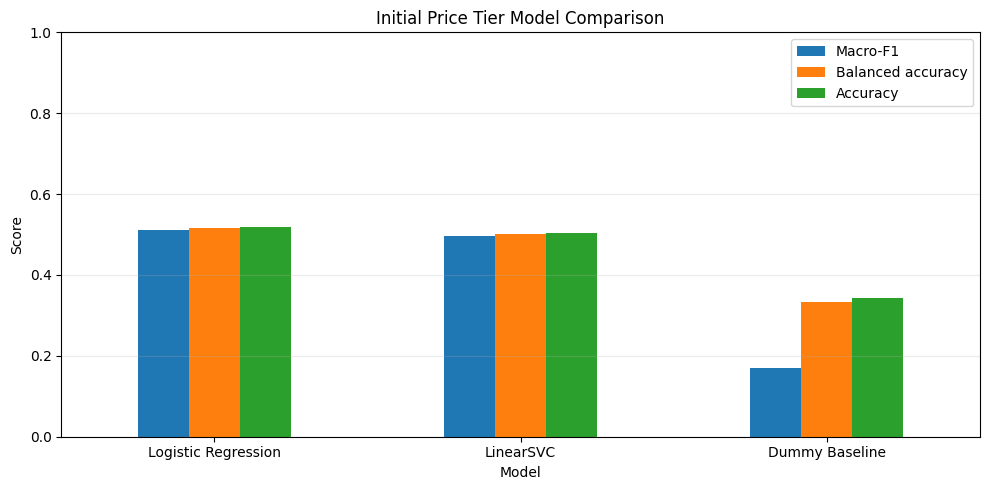

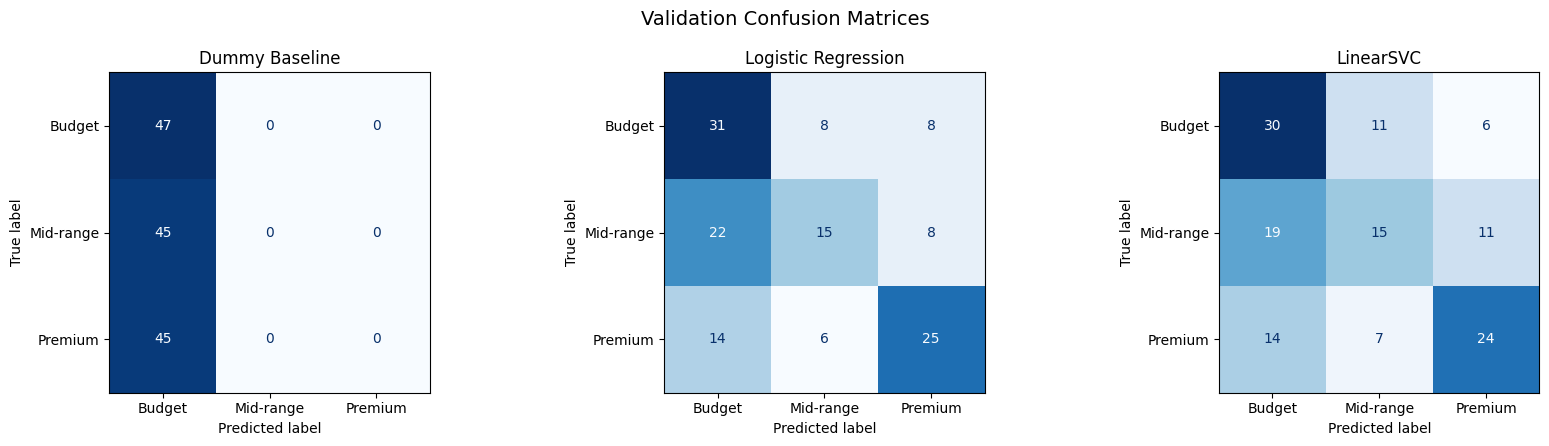

In [11]:
# ============================================================
# Step 4.5: Plot model comparison and confusion matrices
# ============================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
)


comparison_plot_data = (
    initial_model_comparison
    .set_index("method")[
        [
            "validation_macro_f1",
            "validation_balanced_accuracy",
            "validation_accuracy",
        ]
    ]
)

comparison_figure, comparison_axis = (
    plt.subplots(
        figsize=(10, 5),
    )
)

comparison_plot_data.plot(
    kind="bar",
    ax=comparison_axis,
)

comparison_axis.set_title(
    "Initial Price Tier Model Comparison"
)

comparison_axis.set_xlabel(
    "Model"
)

comparison_axis.set_ylabel(
    "Score"
)

comparison_axis.set_ylim(
    0,
    1,
)

comparison_axis.legend(
    [
        "Macro-F1",
        "Balanced accuracy",
        "Accuracy",
    ]
)

comparison_axis.grid(
    axis="y",
    alpha=0.25,
)

plt.xticks(
    rotation=0,
)

plt.tight_layout()
plt.show()


confusion_figure, confusion_axes = (
    plt.subplots(
        1,
        len(trained_models),
        figsize=(17, 4.5),
    )
)

for axis, (
    method_name,
    fitted_model,
) in zip(
    confusion_axes,
    trained_models.items(),
):
    predictions = fitted_model.predict(
        X_validation
    )

    ConfusionMatrixDisplay.from_predictions(
        y_validation,
        predictions,
        labels=LABEL_ORDER,
        display_labels=LABEL_ORDER,
        cmap="Blues",
        colorbar=False,
        ax=axis,
    )

    axis.set_title(
        method_name
    )

confusion_figure.suptitle(
    "Validation Confusion Matrices",
    fontsize=14,
)

plt.tight_layout()
plt.show()

In [12]:
# ============================================================
# Step 4.6: Save initial model-comparison reports
# ============================================================

INITIAL_COMPARISON_PATH = (
    REPORT_DIR
    / "initial_model_comparison.csv"
)

INITIAL_CLASS_METRICS_PATH = (
    REPORT_DIR
    / "initial_per_class_metrics.csv"
)

INITIAL_PREDICTIONS_PATH = (
    REPORT_DIR
    / "initial_validation_predictions.csv"
)

COMPARISON_PLOT_PATH = (
    REPORT_DIR
    / "initial_model_comparison.png"
)

CONFUSION_PLOT_PATH = (
    REPORT_DIR
    / "initial_validation_confusion_matrices.png"
)


initial_model_comparison.to_csv(
    INITIAL_COMPARISON_PATH,
    index=False,
    encoding="utf-8-sig",
)

initial_per_class_metrics.to_csv(
    INITIAL_CLASS_METRICS_PATH,
    index=False,
    encoding="utf-8-sig",
)

initial_validation_predictions.to_csv(
    INITIAL_PREDICTIONS_PATH,
    index=False,
    encoding="utf-8-sig",
)

comparison_figure.savefig(
    COMPARISON_PLOT_PATH,
    dpi=300,
    bbox_inches="tight",
)

confusion_figure.savefig(
    CONFUSION_PLOT_PATH,
    dpi=300,
    bbox_inches="tight",
)


print("Step 4 completed successfully.")
print("Comparison:", INITIAL_COMPARISON_PATH)
print("Tier metrics:", INITIAL_CLASS_METRICS_PATH)
print("Predictions:", INITIAL_PREDICTIONS_PATH)
print("Comparison plot:", COMPARISON_PLOT_PATH)
print("Confusion matrices:", CONFUSION_PLOT_PATH)
print("Final-test split remains untouched.")

Step 4 completed successfully.
Comparison: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/price_tier/initial_model_comparison.csv
Tier metrics: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/price_tier/initial_per_class_metrics.csv
Predictions: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/price_tier/initial_validation_predictions.csv
Comparison plot: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/price_tier/initial_model_comparison.png
Confusion matrices: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/price_tier/initial_validation_confusion_matrices.png
Final-test split remains untouched.


In [14]:
# ============================================================
# Step 5.1: Tuning configuration
# ============================================================

from time import perf_counter

from sklearn.calibration import (
    CalibratedClassifierCV,
)
from sklearn.linear_model import (
    LogisticRegression,
)
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    log_loss,
    precision_recall_fscore_support,
)
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC


required_variables = [
    "X_train_transformed",
    "X_validation_transformed",
    "X_train",
    "X_validation",
    "X_final_test",
    "y_train",
    "y_validation",
    "y_final_test",
    "train_data",
    "validation_data",
    "final_test_data",
    "build_preprocessor",
]

missing_variables = [
    variable
    for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise NameError(
        "Rerun Steps 3 and 4. Missing:\n"
        + ", ".join(missing_variables)
    )


LABEL_ORDER = [
    "Budget",
    "Mid-range",
    "Premium",
]

TIER_TO_NUMBER = {
    "Budget": 0,
    "Mid-range": 1,
    "Premium": 2,
}

C_VALUES = [
    0.5,
    1.0,
    2.0,
]

CLASS_WEIGHT_OPTIONS = [
    None,
    "balanced",
]


def calculate_classification_metrics(
    actual,
    predicted,
):
    precision, recall, class_f1, support = (
        precision_recall_fscore_support(
            actual,
            predicted,
            labels=LABEL_ORDER,
            zero_division=0,
        )
    )

    actual_numbers = (
        pd.Series(
            list(actual)
        )
        .map(TIER_TO_NUMBER)
        .to_numpy()
    )

    predicted_numbers = (
        pd.Series(
            list(predicted)
        )
        .map(TIER_TO_NUMBER)
        .to_numpy()
    )

    tier_distance = np.abs(
        actual_numbers
        - predicted_numbers
    )

    metrics = {
        "accuracy": accuracy_score(
            actual,
            predicted,
        ),
        "balanced_accuracy": (
            balanced_accuracy_score(
                actual,
                predicted,
            )
        ),
        "macro_precision": float(
            precision.mean()
        ),
        "macro_recall": float(
            recall.mean()
        ),
        "macro_f1": f1_score(
            actual,
            predicted,
            average="macro",
            zero_division=0,
        ),
        "minimum_class_f1": float(
            class_f1.min()
        ),
        "ordinal_mae": float(
            tier_distance.mean()
        ),
        "severe_error_rate": float(
            (tier_distance == 2).mean()
        ),
    }

    class_metrics = pd.DataFrame(
        {
            "price_tier": LABEL_ORDER,
            "precision": precision,
            "recall": recall,
            "f1": class_f1,
            "support": support,
        }
    )

    return metrics, class_metrics

In [15]:
# ============================================================
# Step 5.2: Efficient validation tuning
# ============================================================

tuning_rows = []


for class_weight in CLASS_WEIGHT_OPTIONS:
    for c_value in C_VALUES:
        models_to_evaluate = {
            "Logistic Regression": (
                LogisticRegression(
                    C=c_value,
                    class_weight=class_weight,
                    solver="liblinear",
                    max_iter=3000,
                    random_state=RANDOM_STATE,
                )
            ),

            "LinearSVC": LinearSVC(
                C=c_value,
                class_weight=class_weight,
                dual=True,
                max_iter=10000,
                random_state=RANDOM_STATE,
            ),
        }

        for model_family, classifier in (
            models_to_evaluate.items()
        ):
            training_start = perf_counter()

            classifier.fit(
                X_train_transformed,
                y_train,
            )

            training_seconds = (
                perf_counter()
                - training_start
            )

            prediction_start = perf_counter()

            predictions = classifier.predict(
                X_validation_transformed
            )

            prediction_seconds = (
                perf_counter()
                - prediction_start
            )

            repeated_predictions = (
                classifier.predict(
                    X_validation_transformed
                )
            )

            metrics, _ = (
                calculate_classification_metrics(
                    y_validation,
                    predictions,
                )
            )

            tuning_rows.append(
                {
                    "model_family": model_family,
                    "C": c_value,
                    "class_weight": (
                        "none"
                        if class_weight is None
                        else class_weight
                    ),
                    "validation_accuracy": (
                        metrics["accuracy"]
                    ),
                    "validation_balanced_accuracy": (
                        metrics[
                            "balanced_accuracy"
                        ]
                    ),
                    "validation_macro_f1": (
                        metrics["macro_f1"]
                    ),
                    "minimum_class_f1": (
                        metrics[
                            "minimum_class_f1"
                        ]
                    ),
                    "ordinal_mae": (
                        metrics["ordinal_mae"]
                    ),
                    "severe_error_rate": (
                        metrics[
                            "severe_error_rate"
                        ]
                    ),
                    "training_seconds": (
                        training_seconds
                    ),
                    "average_response_time_ms": (
                        prediction_seconds
                        / len(X_validation)
                        * 1000
                    ),
                    "deterministic": (
                        np.array_equal(
                            predictions,
                            repeated_predictions,
                        )
                    ),
                }
            )


tuning_results = pd.DataFrame(
    tuning_rows
)

tuning_results = (
    tuning_results
    .sort_values(
        [
            "validation_macro_f1",
            "validation_balanced_accuracy",
            "minimum_class_f1",
            "ordinal_mae",
            "average_response_time_ms",
        ],
        ascending=[
            False,
            False,
            False,
            True,
            True,
        ],
    )
    .reset_index(drop=True)
)

display(
    tuning_results.round(4)
)

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,model_family,C,class_weight,validation_accuracy,validation_balanced_accuracy,validation_macro_f1,minimum_class_f1,ordinal_mae,severe_error_rate,training_seconds,average_response_time_ms,deterministic
0,Logistic Regression,2.0,balanced,0.5328,0.5307,0.5254,0.4267,0.6204,0.1533,0.1607,0.0029,True
1,LinearSVC,0.5,balanced,0.5328,0.5307,0.5237,0.4000,0.6058,0.1387,6.9929,0.0038,True
2,LinearSVC,0.5,none,0.5328,0.5307,0.5237,0.4000,0.6058,0.1387,5.3802,0.0039,True
3,Logistic Regression,2.0,none,0.5255,0.5232,0.5161,0.4054,0.6277,0.1533,0.1340,0.0035,True
4,Logistic Regression,1.0,balanced,0.5182,0.5162,0.5102,0.4054,0.6423,0.1606,0.1038,0.0027,True
5,Logistic Regression,0.5,none,0.5109,0.5084,0.5037,0.4167,0.6715,0.1825,0.2770,0.0365,True
6,LinearSVC,1.0,none,0.5109,0.5091,0.5028,0.3947,0.6423,0.1533,8.1247,0.0036,True
7,LinearSVC,1.0,balanced,0.5109,0.5091,0.5028,0.3947,0.6423,0.1533,7.6997,0.0036,True
8,Logistic Regression,1.0,none,0.5036,0.5013,0.4943,0.3836,0.6642,0.1679,0.1262,0.0054,True
9,LinearSVC,2.0,balanced,0.5036,0.5013,0.4907,0.3467,0.6350,0.1387,8.4556,0.0058,True


In [16]:
# ============================================================
# Step 5.3: Best configuration per model family
# ============================================================

best_family_configurations = (
    tuning_results
    .sort_values(
        [
            "validation_macro_f1",
            "validation_balanced_accuracy",
            "minimum_class_f1",
            "ordinal_mae",
            "average_response_time_ms",
        ],
        ascending=[
            False,
            False,
            False,
            True,
            True,
        ],
    )
    .groupby(
        "model_family",
        group_keys=False,
    )
    .head(1)
    .reset_index(drop=True)
)

display(
    best_family_configurations.round(4)
)


best_logistic_row = (
    best_family_configurations[
        best_family_configurations[
            "model_family"
        ].eq("Logistic Regression")
    ]
    .iloc[0]
)

best_svc_row = (
    best_family_configurations[
        best_family_configurations[
            "model_family"
        ].eq("LinearSVC")
    ]
    .iloc[0]
)


def restore_class_weight(value):
    if value == "none":
        return None

    return value


best_logistic_parameters = {
    "C": float(
        best_logistic_row["C"]
    ),
    "class_weight": restore_class_weight(
        best_logistic_row[
            "class_weight"
        ]
    ),
}

best_svc_parameters = {
    "C": float(
        best_svc_row["C"]
    ),
    "class_weight": restore_class_weight(
        best_svc_row[
            "class_weight"
        ]
    ),
}


print(
    "Best Logistic Regression parameters:",
    best_logistic_parameters,
)

print(
    "Best LinearSVC parameters:",
    best_svc_parameters,
)

,model_family,C,class_weight,validation_accuracy,validation_balanced_accuracy,validation_macro_f1,minimum_class_f1,ordinal_mae,severe_error_rate,training_seconds,average_response_time_ms,deterministic
0,Logistic Regression,2.0,balanced,0.5328,0.5307,0.5254,0.4267,0.6204,0.1533,0.1607,0.0029,True
1,LinearSVC,0.5,balanced,0.5328,0.5307,0.5237,0.4000,0.6058,0.1387,6.9929,0.0038,True


Best Logistic Regression parameters: {'C': 2.0, 'class_weight': 'balanced'}
Best LinearSVC parameters: {'C': 0.5, 'class_weight': 'balanced'}


In [21]:
# ============================================================
# Step 5.4: Build final validation candidates
# ============================================================

from sklearn.calibration import (
    CalibratedClassifierCV,
)
from sklearn.metrics import log_loss
from sklearn.pipeline import Pipeline


def create_calibrated_svc(
    c_value,
    class_weight,
):
    base_svc = LinearSVC(
        C=c_value,
        class_weight=class_weight,
        dual=True,
        max_iter=10000,
        random_state=RANDOM_STATE,
    )

    try:
        return CalibratedClassifierCV(
            estimator=base_svc,
            method="sigmoid",
            cv=3,
        )
    except TypeError:
        # Compatibility with older scikit-learn.
        return CalibratedClassifierCV(
            base_estimator=base_svc,
            method="sigmoid",
            cv=3,
        )


tuned_candidate_pipelines = {
    "Tuned Logistic Regression": Pipeline(
        steps=[
            (
                "preprocessor",
                build_preprocessor(),
            ),
            (
                "classifier",
                LogisticRegression(
                    C=best_logistic_parameters[
                        "C"
                    ],
                    class_weight=(
                        best_logistic_parameters[
                            "class_weight"
                        ]
                    ),
                    solver="liblinear",
                    max_iter=3000,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    ),

    "Calibrated LinearSVC": Pipeline(
        steps=[
            (
                "preprocessor",
                build_preprocessor(),
            ),
            (
                "classifier",
                create_calibrated_svc(
                    c_value=(
                        best_svc_parameters["C"]
                    ),
                    class_weight=(
                        best_svc_parameters[
                            "class_weight"
                        ]
                    ),
                ),
            ),
        ]
    ),
}


def order_probabilities(
    model,
    probabilities,
):
    model_classes = list(
        model.classes_
    )

    return np.column_stack(
        [
            probabilities[
                :,
                model_classes.index(label),
            ]
            for label in LABEL_ORDER
        ]
    )


def evaluate_probability_pipeline(
    method_name,
    pipeline,
):
    training_start = perf_counter()

    pipeline.fit(
        X_train,
        y_train,
    )

    training_seconds = (
        perf_counter()
        - training_start
    )

    prediction_start = perf_counter()

    predictions = pipeline.predict(
        X_validation
    )

    probabilities = pipeline.predict_proba(
        X_validation
    )

    prediction_seconds = (
        perf_counter()
        - prediction_start
    )

    probabilities = order_probabilities(
        pipeline,
        probabilities,
    )

    repeated_predictions = pipeline.predict(
        X_validation
    )

    metrics, class_metrics = (
        calculate_classification_metrics(
            y_validation,
            predictions,
        )
    )

    result = {
        "method": method_name,
        "validation_accuracy": (
            metrics["accuracy"]
        ),
        "validation_balanced_accuracy": (
            metrics["balanced_accuracy"]
        ),
        "validation_macro_precision": (
            metrics["macro_precision"]
        ),
        "validation_macro_recall": (
            metrics["macro_recall"]
        ),
        "validation_macro_f1": (
            metrics["macro_f1"]
        ),
        "minimum_class_f1": (
            metrics["minimum_class_f1"]
        ),
        "ordinal_mae": (
            metrics["ordinal_mae"]
        ),
        "severe_error_rate": (
            metrics["severe_error_rate"]
        ),
        "log_loss": log_loss(
            y_validation,
            probabilities,
            labels=LABEL_ORDER,
        ),
        "average_confidence": float(
            probabilities.max(axis=1).mean()
        ),
        "training_seconds": training_seconds,
        "average_response_time_ms": (
            prediction_seconds
            / len(X_validation)
            * 1000
        ),
        "deterministic": np.array_equal(
            predictions,
            repeated_predictions,
        ),
    }

    class_metrics.insert(
        0,
        "method",
        method_name,
    )

    return (
        result,
        class_metrics,
        predictions,
        probabilities,
    )

In [22]:
# ============================================================
# Step 5.5: Final validation comparison and selection
# ============================================================

tuned_validation_rows = []
tuned_class_frames = []
tuned_validation_outputs = {}


for method_name, pipeline in (
    tuned_candidate_pipelines.items()
):
    print(
        "Evaluating:",
        method_name,
    )

    (
        result,
        class_metrics,
        predictions,
        probabilities,
    ) = evaluate_probability_pipeline(
        method_name,
        pipeline,
    )

    tuned_validation_rows.append(
        result
    )

    tuned_class_frames.append(
        class_metrics
    )

    tuned_validation_outputs[
        method_name
    ] = {
        "predictions": predictions,
        "probabilities": probabilities,
    }


tuned_validation_comparison = (
    pd.DataFrame(
        tuned_validation_rows
    )
    .sort_values(
        [
            "validation_macro_f1",
            "validation_balanced_accuracy",
            "minimum_class_f1",
            "ordinal_mae",
            "log_loss",
            "average_response_time_ms",
        ],
        ascending=[
            False,
            False,
            False,
            True,
            True,
            True,
        ],
    )
    .reset_index(drop=True)
)

tuned_validation_class_metrics = (
    pd.concat(
        tuned_class_frames,
        ignore_index=True,
    )
)

selected_method = (
    tuned_validation_comparison
    .iloc[0]["method"]
)

selected_validation_pipeline = (
    tuned_candidate_pipelines[
        selected_method
    ]
)


if selected_method == (
    "Tuned Logistic Regression"
):
    selected_family = (
        "Logistic Regression"
    )

    selected_parameters = (
        best_logistic_parameters
    )
else:
    selected_family = "LinearSVC"

    selected_parameters = (
        best_svc_parameters
    )


display(
    tuned_validation_comparison.round(4)
)

display(
    tuned_validation_class_metrics.round(4)
)

print("Selected method:", selected_method)
print("Selected family:", selected_family)
print(
    "Selected parameters:",
    selected_parameters,
)
print("Selection used final-test data: False")

Evaluating: Tuned Logistic Regression
Evaluating: Calibrated LinearSVC


,method,validation_accuracy,validation_balanced_accuracy,validation_macro_precision,validation_macro_recall,validation_macro_f1,minimum_class_f1,ordinal_mae,severe_error_rate,log_loss,average_confidence,training_seconds,average_response_time_ms,deterministic
0,Tuned Logistic Regression,0.5328,0.5307,0.5453,0.5307,0.5254,0.4267,0.6204,0.1533,1.0157,0.5104,0.7615,1.1097,True
1,Calibrated LinearSVC,0.5109,0.5078,0.5360,0.5078,0.4980,0.4000,0.6715,0.1825,1.0133,0.4453,7.9754,1.0952,True


,method,price_tier,precision,recall,f1,support
0,Tuned Logistic Regression,Budget,0.4776,0.6809,0.5614,47
1,Tuned Logistic Regression,Mid-range,0.5333,0.3556,0.4267,45
2,Tuned Logistic Regression,Premium,0.6250,0.5556,0.5882,45
3,Calibrated LinearSVC,Budget,0.4533,0.7234,0.5574,47
4,Calibrated LinearSVC,Mid-range,0.5600,0.3111,0.4000,45
5,Calibrated LinearSVC,Premium,0.5946,0.4889,0.5366,45


Selected method: Tuned Logistic Regression
Selected family: Logistic Regression
Selected parameters: {'C': 2.0, 'class_weight': 'balanced'}
Selection used final-test data: False


In [24]:
# ============================================================
# Step 5.5: Final validation comparison and selection
# ============================================================

tuned_validation_rows = []
tuned_class_frames = []
tuned_validation_outputs = {}


for method_name, pipeline in (
    tuned_candidate_pipelines.items()
):
    print(
        "Evaluating:",
        method_name,
    )

    (
        result,
        class_metrics,
        predictions,
        probabilities,
    ) = evaluate_probability_pipeline(
        method_name,
        pipeline,
    )

    tuned_validation_rows.append(
        result
    )

    tuned_class_frames.append(
        class_metrics
    )

    tuned_validation_outputs[
        method_name
    ] = {
        "predictions": predictions,
        "probabilities": probabilities,
    }


tuned_validation_comparison = (
    pd.DataFrame(
        tuned_validation_rows
    )
    .sort_values(
        [
            "validation_macro_f1",
            "validation_balanced_accuracy",
            "minimum_class_f1",
            "ordinal_mae",
            "log_loss",
            "average_response_time_ms",
        ],
        ascending=[
            False,
            False,
            False,
            True,
            True,
            True,
        ],
    )
    .reset_index(drop=True)
)

tuned_validation_class_metrics = (
    pd.concat(
        tuned_class_frames,
        ignore_index=True,
    )
)

selected_method = (
    tuned_validation_comparison
    .iloc[0]["method"]
)

selected_validation_pipeline = (
    tuned_candidate_pipelines[
        selected_method
    ]
)


if selected_method == (
    "Tuned Logistic Regression"
):
    selected_family = (
        "Logistic Regression"
    )

    selected_parameters = (
        best_logistic_parameters
    )
else:
    selected_family = "LinearSVC"

    selected_parameters = (
        best_svc_parameters
    )


display(
    tuned_validation_comparison.round(4)
)

display(
    tuned_validation_class_metrics.round(4)
)

print("Selected method:", selected_method)
print("Selected family:", selected_family)
print(
    "Selected parameters:",
    selected_parameters,
)
print("Selection used final-test data: False")

Evaluating: Tuned Logistic Regression
Evaluating: Calibrated LinearSVC


,method,validation_accuracy,validation_balanced_accuracy,validation_macro_precision,validation_macro_recall,validation_macro_f1,minimum_class_f1,ordinal_mae,severe_error_rate,log_loss,average_confidence,training_seconds,average_response_time_ms,deterministic
0,Tuned Logistic Regression,0.5328,0.5307,0.5453,0.5307,0.5254,0.4267,0.6204,0.1533,1.0157,0.5104,1.3994,1.5401,True
1,Calibrated LinearSVC,0.5109,0.5078,0.5360,0.5078,0.4980,0.4000,0.6715,0.1825,1.0133,0.4453,7.9004,1.0565,True


,method,price_tier,precision,recall,f1,support
0,Tuned Logistic Regression,Budget,0.4776,0.6809,0.5614,47
1,Tuned Logistic Regression,Mid-range,0.5333,0.3556,0.4267,45
2,Tuned Logistic Regression,Premium,0.6250,0.5556,0.5882,45
3,Calibrated LinearSVC,Budget,0.4533,0.7234,0.5574,47
4,Calibrated LinearSVC,Mid-range,0.5600,0.3111,0.4000,45
5,Calibrated LinearSVC,Premium,0.5946,0.4889,0.5366,45


Selected method: Tuned Logistic Regression
Selected family: Logistic Regression
Selected parameters: {'C': 2.0, 'class_weight': 'balanced'}
Selection used final-test data: False


In [25]:
# ============================================================
# Step 5.6: Final holdout evaluation
# ============================================================

test_prediction_start = perf_counter()

final_test_predictions = (
    selected_validation_pipeline.predict(
        X_final_test
    )
)

final_test_probabilities = (
    selected_validation_pipeline.predict_proba(
        X_final_test
    )
)

test_prediction_seconds = (
    perf_counter()
    - test_prediction_start
)

final_test_probabilities = (
    order_probabilities(
        selected_validation_pipeline,
        final_test_probabilities,
    )
)

repeated_final_predictions = (
    selected_validation_pipeline.predict(
        X_final_test
    )
)

test_metrics, final_test_class_metrics = (
    calculate_classification_metrics(
        y_final_test,
        final_test_predictions,
    )
)


final_test_evaluation = pd.DataFrame(
    [
        {
            "method": selected_method,
            "accuracy": (
                test_metrics["accuracy"]
            ),
            "balanced_accuracy": (
                test_metrics[
                    "balanced_accuracy"
                ]
            ),
            "macro_precision": (
                test_metrics[
                    "macro_precision"
                ]
            ),
            "macro_recall": (
                test_metrics[
                    "macro_recall"
                ]
            ),
            "macro_f1": (
                test_metrics["macro_f1"]
            ),
            "minimum_class_f1": (
                test_metrics[
                    "minimum_class_f1"
                ]
            ),
            "ordinal_mae": (
                test_metrics[
                    "ordinal_mae"
                ]
            ),
            "severe_error_rate": (
                test_metrics[
                    "severe_error_rate"
                ]
            ),
            "log_loss": log_loss(
                y_final_test,
                final_test_probabilities,
                labels=LABEL_ORDER,
            ),
            "average_confidence": float(
                final_test_probabilities
                .max(axis=1)
                .mean()
            ),
            "average_response_time_ms": (
                test_prediction_seconds
                / len(X_final_test)
                * 1000
            ),
            "deterministic": np.array_equal(
                final_test_predictions,
                repeated_final_predictions,
            ),
            "evaluated_products": (
                len(X_final_test)
            ),
        }
    ]
)


final_test_class_metrics.insert(
    0,
    "method",
    selected_method,
)


final_test_prediction_report = pd.DataFrame(
    {
        "asin": (
            final_test_data[
                "asin"
            ].values
        ),
        "actual_price_tier": (
            y_final_test.values
        ),
        "predicted_price_tier": (
            final_test_predictions
        ),
        "prediction_confidence": (
            final_test_probabilities
            .max(axis=1)
        ),
        "probability_budget": (
            final_test_probabilities[:, 0]
        ),
        "probability_mid_range": (
            final_test_probabilities[:, 1]
        ),
        "probability_premium": (
            final_test_probabilities[:, 2]
        ),
    }
)


display(
    final_test_evaluation.round(4)
)

display(
    final_test_class_metrics.round(4)
)

display(
    final_test_prediction_report.head()
)

,method,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,minimum_class_f1,ordinal_mae,severe_error_rate,log_loss,average_confidence,average_response_time_ms,deterministic,evaluated_products
0,Tuned Logistic Regression,0.4964,0.4946,0.4922,0.4946,0.492,0.4419,0.6569,0.1533,1.1023,0.5146,5.5935,True,137


,method,price_tier,precision,recall,f1,support
0,Tuned Logistic Regression,Budget,0.5370,0.6170,0.5743,47
1,Tuned Logistic Regression,Mid-range,0.4634,0.4222,0.4419,45
2,Tuned Logistic Regression,Premium,0.4762,0.4444,0.4598,45


,asin,actual_price_tier,predicted_price_tier,prediction_confidence,probability_budget,probability_mid_range,probability_premium
0,B0012OGF6Q,Mid-range,Mid-range,0.426702,0.424350,0.426702,0.148948
1,B0CTCT2PKN,Budget,Budget,0.588775,0.588775,0.169758,0.241467
2,B0DY2PB7RB,Premium,Budget,0.505443,0.505443,0.332419,0.162138
3,B071VJPRD4,Budget,Mid-range,0.356148,0.291562,0.356148,0.352290
4,B0B69LJ3BD,Premium,Premium,0.458127,0.246932,0.294941,0.458127


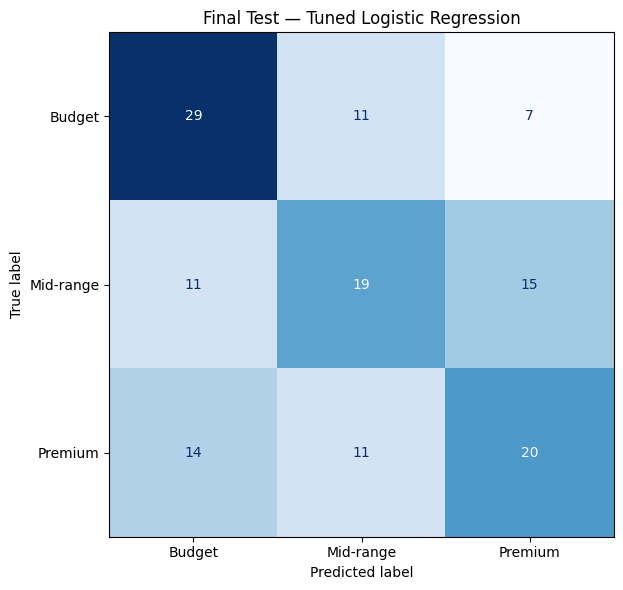

In [26]:
# ============================================================
# Step 5.7: Final-test confusion matrix
# ============================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
)


final_confusion_figure, final_confusion_axis = (
    plt.subplots(
        figsize=(7, 6)
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_final_test,
    final_test_predictions,
    labels=LABEL_ORDER,
    display_labels=LABEL_ORDER,
    cmap="Blues",
    colorbar=False,
    ax=final_confusion_axis,
)

final_confusion_axis.set_title(
    f"Final Test — {selected_method}"
)

plt.tight_layout()
plt.show()

In [27]:
# ============================================================
# Step 5.8: Refit selected model on train + validation
# ============================================================

development_data = pd.concat(
    [
        train_data,
        validation_data,
    ],
    ignore_index=True,
)

X_development = development_data[
    MODEL_FEATURES
]

y_development = development_data[
    TARGET_COLUMN
]


if selected_family == (
    "Logistic Regression"
):
    deployment_classifier = (
        LogisticRegression(
            C=selected_parameters["C"],
            class_weight=(
                selected_parameters[
                    "class_weight"
                ]
            ),
            solver="liblinear",
            max_iter=3000,
            random_state=RANDOM_STATE,
        )
    )
else:
    deployment_classifier = (
        create_calibrated_svc(
            c_value=(
                selected_parameters["C"]
            ),
            class_weight=(
                selected_parameters[
                    "class_weight"
                ]
            ),
        )
    )


deployment_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            build_preprocessor(),
        ),
        (
            "classifier",
            deployment_classifier,
        ),
    ]
)

deployment_pipeline.fit(
    X_development,
    y_development,
)

deployment_check_one = (
    deployment_pipeline.predict(
        X_development.head(20)
    )
)

deployment_check_two = (
    deployment_pipeline.predict(
        X_development.head(20)
    )
)

if not np.array_equal(
    deployment_check_one,
    deployment_check_two,
):
    raise ValueError(
        "Deployment predictions are not deterministic."
    )


print(
    "Deployment training products:",
    len(development_data),
)

print(
    "Final-test products excluded from refitting:",
    len(final_test_data),
)

print(
    "Deployment predictions deterministic: True"
)

Deployment training products: 776
Final-test products excluded from refitting: 137
Deployment predictions deterministic: True


In [28]:
# ============================================================
# Step 5.9: Save final model-selection outputs
# ============================================================

import joblib


TUNING_RESULTS_PATH = (
    REPORT_DIR
    / "price_tier_tuning_results.csv"
)

VALIDATION_COMPARISON_PATH = (
    REPORT_DIR
    / "tuned_validation_comparison.csv"
)

VALIDATION_CLASS_PATH = (
    REPORT_DIR
    / "tuned_validation_class_metrics.csv"
)

FINAL_EVALUATION_PATH = (
    REPORT_DIR
    / "final_price_tier_evaluation.csv"
)

FINAL_CLASS_PATH = (
    REPORT_DIR
    / "final_price_tier_class_metrics.csv"
)

FINAL_PREDICTIONS_PATH = (
    REPORT_DIR
    / "final_price_tier_predictions.csv"
)

FINAL_CONFUSION_PATH = (
    REPORT_DIR
    / "final_price_tier_confusion_matrix.png"
)

MODEL_PATH = (
    MODEL_DIR
    / "price_tier_pipeline.joblib"
)

DECISION_PATH = (
    MODEL_DIR
    / "price_tier_model_decision.json"
)


tuning_results.to_csv(
    TUNING_RESULTS_PATH,
    index=False,
    encoding="utf-8-sig",
)

tuned_validation_comparison.to_csv(
    VALIDATION_COMPARISON_PATH,
    index=False,
    encoding="utf-8-sig",
)

tuned_validation_class_metrics.to_csv(
    VALIDATION_CLASS_PATH,
    index=False,
    encoding="utf-8-sig",
)

final_test_evaluation.to_csv(
    FINAL_EVALUATION_PATH,
    index=False,
    encoding="utf-8-sig",
)

final_test_class_metrics.to_csv(
    FINAL_CLASS_PATH,
    index=False,
    encoding="utf-8-sig",
)

final_test_prediction_report.to_csv(
    FINAL_PREDICTIONS_PATH,
    index=False,
    encoding="utf-8-sig",
)

final_confusion_figure.savefig(
    FINAL_CONFUSION_PATH,
    dpi=300,
    bbox_inches="tight",
)

joblib.dump(
    deployment_pipeline,
    MODEL_PATH,
)


def make_json_safe(value):
    if isinstance(
        value,
        np.generic,
    ):
        return value.item()

    return value


decision_metadata = {
    "selected_method": selected_method,
    "selected_family": selected_family,
    "selected_parameters": {
        key: make_json_safe(value)
        for key, value
        in selected_parameters.items()
    },
    "selection_primary_metric": (
        "validation_macro_f1"
    ),
    "selection_used_final_test": False,
    "final_test_evaluated_once": True,
    "price_used_as_model_feature": False,
    "deployment_training_products": int(
        len(development_data)
    ),
    "final_test_products": int(
        len(final_test_data)
    ),
    "final_test_results": {
        key: make_json_safe(value)
        for key, value
        in final_test_evaluation
        .iloc[0]
        .to_dict()
        .items()
    },
}

with open(
    DECISION_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        decision_metadata,
        file,
        indent=2,
        ensure_ascii=False,
    )


print("Step 5 completed successfully.")
print("Selected model:", selected_method)
print("Model artifact:", MODEL_PATH)
print("Decision metadata:", DECISION_PATH)
print("Final evaluation:", FINAL_EVALUATION_PATH)
print("Final confusion matrix:", FINAL_CONFUSION_PATH)

Step 5 completed successfully.
Selected model: Tuned Logistic Regression
Model artifact: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/price_tier/price_tier_pipeline.joblib
Decision metadata: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/price_tier/price_tier_model_decision.json
Final evaluation: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/price_tier/final_price_tier_evaluation.csv
Final confusion matrix: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/price_tier/final_price_tier_confusion_matrix.png


In [2]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/"
    "Amazon-Marketplace-Product-Intelligence-Platform-BJIT"
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports" / "price_tier"
MODEL_DIR = PROJECT_ROOT / "models" / "price_tier"

print("MODEL_DIR:", MODEL_DIR)
print("Model directory exists:", MODEL_DIR.exists())

Mounted at /content/drive
MODEL_DIR: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/price_tier
Model directory exists: True


In [3]:
# ============================================================
# Step 6.1: Load final model and complete catalogue
# ============================================================

import json
import joblib
import re

import numpy as np
import pandas as pd

from scipy import sparse


MODEL_PATH = (
    MODEL_DIR
    / "price_tier_pipeline.joblib"
)

DECISION_PATH = (
    MODEL_DIR
    / "price_tier_model_decision.json"
)

COMPLETE_DATA_PATH = (
    PROCESSED_DIR
    / "products_price_tier_clean.csv"
)

FEATURE_CONFIG_PATH = (
    REPORT_DIR
    / "price_tier_feature_config.json"
)


required_paths = [
    MODEL_PATH,
    DECISION_PATH,
    COMPLETE_DATA_PATH,
    FEATURE_CONFIG_PATH,
]

missing_paths = [
    str(path)
    for path in required_paths
    if not path.exists()
]

if missing_paths:
    raise FileNotFoundError(
        "Required Step 5 files are missing:\n"
        + "\n".join(missing_paths)
    )


price_tier_pipeline = joblib.load(
    MODEL_PATH
)

complete_products = pd.read_csv(
    COMPLETE_DATA_PATH,
    dtype={"asin": str},
    low_memory=False,
)

with open(
    DECISION_PATH,
    encoding="utf-8",
) as file:
    model_decision = json.load(file)

with open(
    FEATURE_CONFIG_PATH,
    encoding="utf-8",
) as file:
    feature_config = json.load(file)


MODEL_FEATURES = feature_config[
    "all_model_features"
]

LABEL_ORDER = [
    "Budget",
    "Mid-range",
    "Premium",
]


print("Complete catalogue:", len(complete_products))
print(
    "Selected method:",
    model_decision["selected_method"],
)
print("Model features:", len(MODEL_FEATURES))
print(
    "Price used as model feature:",
    feature_config[
        "price_used_as_model_feature"
    ],
)

Complete catalogue: 981
Selected method: Tuned Logistic Regression
Model features: 13
Price used as model feature: False


In [4]:
# ============================================================
# Step 6.2: Prepare complete catalogue features
# ============================================================

PRICE_AMOUNT_PATTERN = re.compile(
    r"""
    (?:
        [$£€]\s*\d[\d,.]*
        |
        \b(?:usd|gbp|eur)\s*\d[\d,.]*
    )
    """,
    flags=re.IGNORECASE | re.VERBOSE,
)

MISSING_CATEGORY_VALUES = {
    "",
    "nan",
    "none",
    "null",
    "unknown",
    "not available",
}


def prepare_text(value):
    if pd.isna(value):
        return ""

    value = str(value).strip()

    value = PRICE_AMOUNT_PATTERN.sub(
        " ",
        value,
    )

    value = re.sub(
        r"\s+",
        " ",
        value,
    ).strip()

    return value


def prepare_catalogue_features(dataframe):
    prepared = dataframe.copy()

    prepared["asin"] = (
        prepared["asin"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.upper()
    )

    prepared["title"] = (
        prepared["title"]
        .map(prepare_text)
    )

    prepared["description"] = (
        prepared["description"]
        .map(prepare_text)
    )

    prepared["title_missing"] = (
        prepared["title"]
        .eq("")
        .astype(int)
    )

    prepared["description_missing"] = (
        prepared["description"]
        .eq("")
        .astype(int)
    )

    prepared["combined_text"] = (
        prepared["title"]
        + " "
        + prepared["description"]
    ).str.strip()

    prepared["title_length"] = (
        prepared["title"]
        .str.split()
        .str.len()
        .fillna(0)
        .astype(int)
    )

    prepared["description_length"] = (
        prepared["description"]
        .str.split()
        .str.len()
        .fillna(0)
        .astype(int)
    )

    for column in [
        "brand",
        "keyword",
        "marketplace",
    ]:
        cleaned_values = (
            prepared[column]
            .fillna("")
            .astype(str)
            .str.strip()
        )

        missing_mask = (
            cleaned_values
            .str.lower()
            .isin(
                MISSING_CATEGORY_VALUES
            )
        )

        cleaned_values.loc[
            missing_mask
        ] = "Unknown"

        prepared[column] = (
            cleaned_values
        )

    prepared["brand_missing"] = (
        prepared["brand"]
        .eq("Unknown")
        .astype(int)
    )

    prepared["review_count"] = (
        pd.to_numeric(
            prepared["review_count"],
            errors="coerce",
        )
        .abs()
    )

    prepared["review_count_missing"] = (
        prepared["review_count"]
        .isna()
        .astype(int)
    )

    prepared["log_review_count"] = (
        np.log1p(
            prepared["review_count"]
        )
    )

    prepared["average_rating"] = (
        pd.to_numeric(
            prepared["average_rating"],
            errors="coerce",
        )
    )

    prepared["average_rating"] = (
        prepared["average_rating"]
        .where(
            prepared["average_rating"]
            .between(
                0,
                5,
                inclusive="both",
            )
        )
    )

    prepared["rating_missing"] = (
        prepared["average_rating"]
        .isna()
        .astype(int)
    )

    return prepared


prepared_products = (
    prepare_catalogue_features(
        complete_products
    )
)

missing_model_features = [
    feature
    for feature in MODEL_FEATURES
    if feature not in prepared_products.columns
]

if missing_model_features:
    raise ValueError(
        "Prepared model features are missing:\n"
        + ", ".join(missing_model_features)
    )


FORBIDDEN_FEATURES = {
    "price",
    "budget_upper",
    "midrange_upper",
    "threshold_source",
    "price_tier",
    "currency",
    "asin",
    "product_url",
    "image_url",
}

feature_leakage = (
    set(MODEL_FEATURES)
    & FORBIDDEN_FEATURES
)

if feature_leakage:
    raise ValueError(
        "Forbidden features detected:\n"
        + ", ".join(
            sorted(feature_leakage)
        )
    )


X_complete = prepared_products[
    MODEL_FEATURES
]


print("Prepared products:", len(X_complete))
print("Missing model columns:", len(missing_model_features))
print("Forbidden feature overlap:", len(feature_leakage))
print("Price passed to model: False")

Prepared products: 981
Missing model columns: 0
Forbidden feature overlap: 0
Price passed to model: False


In [5]:
# ============================================================
# Step 6.3: Predict tiers for the complete catalogue
# ============================================================

prediction_labels = (
    price_tier_pipeline.predict(
        X_complete
    )
)

raw_probabilities = (
    price_tier_pipeline.predict_proba(
        X_complete
    )
)

model_classes = list(
    price_tier_pipeline.classes_
)

ordered_probabilities = np.column_stack(
    [
        raw_probabilities[
            :,
            model_classes.index(label),
        ]
        for label in LABEL_ORDER
    ]
)


repeated_predictions = (
    price_tier_pipeline.predict(
        X_complete
    )
)

if not np.array_equal(
    prediction_labels,
    repeated_predictions,
):
    raise ValueError(
        "Predictions are not deterministic."
    )


prediction_results = pd.DataFrame(
    {
        "asin": (
            prepared_products["asin"]
        ),
        "predicted_price_tier": (
            prediction_labels
        ),
        "prediction_confidence": (
            ordered_probabilities
            .max(axis=1)
        ),
        "probability_budget": (
            ordered_probabilities[:, 0]
        ),
        "probability_mid_range": (
            ordered_probabilities[:, 1]
        ),
        "probability_premium": (
            ordered_probabilities[:, 2]
        ),
    }
)


if "price_tier" in complete_products.columns:
    prediction_results[
        "reference_price_tier"
    ] = complete_products[
        "price_tier"
    ]
else:
    prediction_results[
        "reference_price_tier"
    ] = pd.NA


prediction_results[
    "reference_tier_available"
] = (
    prediction_results[
        "reference_price_tier"
    ]
    .notna()
)


display(
    prediction_results.head()
)

display(
    prediction_results[
        "predicted_price_tier"
    ]
    .value_counts()
    .reindex(
        LABEL_ORDER,
        fill_value=0,
    )
    .rename_axis("predicted_tier")
    .reset_index(name="product_count")
)

print(
    "Products predicted:",
    len(prediction_results),
)

print(
    "Products with missing prices also predicted:",
    int(
        (
            complete_products["price"].isna()
        ).sum()
    ),
)

print("Predictions deterministic: True")

,asin,predicted_price_tier,prediction_confidence,probability_budget,probability_mid_range,probability_premium,reference_price_tier,reference_tier_available
0,B003GMP03Q,Premium,0.547729,0.401052,0.051219,0.547729,Budget,True
1,B0CW6KY2ZK,Mid-range,0.808328,0.082792,0.808328,0.108880,Mid-range,True
2,B001U0OWTO,Mid-range,0.615068,0.200279,0.615068,0.184653,Mid-range,True
3,B07XJLD2BL,Premium,0.536908,0.361124,0.101968,0.536908,Premium,True
4,B09XVLKGFT,Premium,0.532692,0.383442,0.083866,0.532692,Premium,True


,predicted_tier,product_count
0,Budget,337
1,Mid-range,307
2,Premium,337


Products predicted: 981
Products with missing prices also predicted: 68
Predictions deterministic: True


In [6]:
# ============================================================
# Step 6.4: Extract important features for each tier
# ============================================================

preprocessor = (
    price_tier_pipeline
    .named_steps["preprocessor"]
)

classifier = (
    price_tier_pipeline
    .named_steps["classifier"]
)

feature_names = np.asarray(
    preprocessor.get_feature_names_out()
)


def extract_linear_coefficients(
    fitted_classifier,
):
    if hasattr(
        fitted_classifier,
        "coef_",
    ):
        return (
            np.asarray(
                fitted_classifier.coef_
            ),
            list(
                fitted_classifier.classes_
            ),
        )

    calibrated_models = getattr(
        fitted_classifier,
        "calibrated_classifiers_",
        None,
    )

    if not calibrated_models:
        raise TypeError(
            "Linear coefficients could not be "
            "extracted from the final classifier."
        )

    coefficient_matrices = []
    estimator_classes = None

    for calibrated_model in calibrated_models:
        estimator = getattr(
            calibrated_model,
            "estimator",
            None,
        )

        if estimator is None:
            estimator = getattr(
                calibrated_model,
                "base_estimator",
                None,
            )

        if estimator is None or not hasattr(
            estimator,
            "coef_",
        ):
            continue

        coefficient_matrices.append(
            np.asarray(
                estimator.coef_
            )
        )

        estimator_classes = list(
            estimator.classes_
        )

    if not coefficient_matrices:
        raise TypeError(
            "No calibrated linear estimator "
            "coefficients were found."
        )

    return (
        np.mean(
            coefficient_matrices,
            axis=0,
        ),
        estimator_classes,
    )


linear_coefficients, coefficient_classes = (
    extract_linear_coefficients(
        classifier
    )
)


def format_feature_name(feature_name):
    feature_name = str(feature_name)

    if feature_name.startswith(
        "text__"
    ):
        return (
            "text term: "
            + feature_name.replace(
                "text__",
                "",
                1,
            )
        )

    if feature_name.startswith(
        "categorical__"
    ):
        value = feature_name.replace(
            "categorical__",
            "",
            1,
        )

        for prefix in [
            "brand_",
            "keyword_",
            "marketplace_",
        ]:
            if value.startswith(prefix):
                column_name = prefix[:-1]

                category_value = value[
                    len(prefix):
                ]

                return (
                    f"{column_name}: "
                    f"{category_value}"
                )

        return value

    numeric_mapping = {
        "numeric__log_review_count": (
            "review-count level"
        ),
        "numeric__average_rating": (
            "average rating"
        ),
        "numeric__title_length": (
            "title length"
        ),
        "numeric__description_length": (
            "description length"
        ),
        "numeric__title_missing": (
            "missing title"
        ),
        "numeric__description_missing": (
            "missing description"
        ),
        "numeric__brand_missing": (
            "missing brand"
        ),
        "numeric__review_count_missing": (
            "missing review count"
        ),
        "numeric__rating_missing": (
            "missing rating"
        ),
    }

    return numeric_mapping.get(
        feature_name,
        feature_name,
    )


feature_summary_rows = []

for tier_name in LABEL_ORDER:
    class_index = coefficient_classes.index(
        tier_name
    )

    tier_coefficients = (
        linear_coefficients[
            class_index
        ]
    )

    top_feature_indices = np.argsort(
        tier_coefficients
    )[::-1][:20]

    for rank, feature_index in enumerate(
        top_feature_indices,
        start=1,
    ):
        feature_summary_rows.append(
            {
                "price_tier": tier_name,
                "rank": rank,
                "raw_feature": (
                    feature_names[
                        feature_index
                    ]
                ),
                "feature": format_feature_name(
                    feature_names[
                        feature_index
                    ]
                ),
                "coefficient": float(
                    tier_coefficients[
                        feature_index
                    ]
                ),
            }
        )


price_tier_feature_summary = pd.DataFrame(
    feature_summary_rows
)

display(
    price_tier_feature_summary[
        price_tier_feature_summary[
            "rank"
        ].le(10)
    ]
)

,price_tier,rank,raw_feature,feature,coefficient
0,Budget,1,categorical__brand_Visit the SUIN Store,brand: Visit the SUIN Store,1.911447
1,Budget,2,categorical__brand_Visit the FNTCASE Store,brand: Visit the FNTCASE Store,1.440041
2,Budget,3,categorical__brand_Visit the Voncerus Store,brand: Visit the Voncerus Store,1.273472
3,Budget,4,categorical__brand_Visit the carori Store,brand: Visit the carori Store,1.126707
4,Budget,5,categorical__brand_Visit the LOVEVOOK Store,brand: Visit the LOVEVOOK Store,1.124712
5,Budget,6,categorical__brand_Visit the CAHAYA Store,brand: Visit the CAHAYA Store,1.119831
6,Budget,7,categorical__brand_Visit the FikShot Store,brand: Visit the FikShot Store,1.105197
7,Budget,8,categorical__brand_Visit the Taja Store,brand: Visit the Taja Store,1.072325
8,Budget,9,categorical__brand_Visit the Cillso Store,brand: Visit the Cillso Store,1.064534
9,Budget,10,categorical__brand_Brand: XIAOWTEK,brand: Brand: XIAOWTEK,1.064508


In [7]:
# ============================================================
# Step 6.5: Generate evidence-based prediction reasons
# ============================================================

transformed_complete_features = (
    preprocessor.transform(
        X_complete
    )
)

coefficient_class_lookup = {
    tier_name: coefficient_classes.index(
        tier_name
    )
    for tier_name in LABEL_ORDER
}


def get_product_signals(
    row_index,
    predicted_tier,
    maximum_signals=3,
):
    class_index = (
        coefficient_class_lookup[
            predicted_tier
        ]
    )

    tier_coefficients = (
        linear_coefficients[
            class_index
        ]
    )

    if sparse.issparse(
        transformed_complete_features
    ):
        contribution_values = (
            transformed_complete_features[
                row_index
            ]
            .multiply(
                tier_coefficients
            )
            .toarray()
            .ravel()
        )
    else:
        contribution_values = (
            transformed_complete_features[
                row_index
            ]
            * tier_coefficients
        )

    ranked_indices = np.argsort(
        contribution_values
    )[::-1]

    selected_signals = []

    for feature_index in ranked_indices:
        if contribution_values[
            feature_index
        ] <= 0:
            break

        signal = format_feature_name(
            feature_names[
                feature_index
            ]
        )

        if signal not in selected_signals:
            selected_signals.append(
                signal
            )

        if len(selected_signals) >= maximum_signals:
            break

    return selected_signals


reason_rows = []

for row_index, prediction_row in (
    prediction_results.iterrows()
):
    predicted_tier = prediction_row[
        "predicted_price_tier"
    ]

    confidence = float(
        prediction_row[
            "prediction_confidence"
        ]
    )

    signals = get_product_signals(
        row_index,
        predicted_tier,
    )

    if signals:
        signal_text = "; ".join(
            signals
        )

        reason = (
            f"Predicted {predicted_tier} with "
            f"{confidence:.1%} confidence. "
            f"Strongest learned signals: "
            f"{signal_text}."
        )
    else:
        reason = (
            f"Predicted {predicted_tier} with "
            f"{confidence:.1%} confidence using "
            "the available product attributes."
        )

    reason_rows.append(
        {
            "explanation_feature_1": (
                signals[0]
                if len(signals) > 0
                else ""
            ),
            "explanation_feature_2": (
                signals[1]
                if len(signals) > 1
                else ""
            ),
            "explanation_feature_3": (
                signals[2]
                if len(signals) > 2
                else ""
            ),
            "prediction_reason": reason,
        }
    )


reason_data = pd.DataFrame(
    reason_rows
)

prediction_results = pd.concat(
    [
        prediction_results,
        reason_data,
    ],
    axis=1,
)


display(
    prediction_results[
        [
            "asin",
            "predicted_price_tier",
            "prediction_confidence",
            "prediction_reason",
        ]
    ].head(10)
)

,asin,predicted_price_tier,prediction_confidence,prediction_reason
0,B003GMP03Q,Premium,0.547729,Predicted Premium with 54.8% confidence. Stron...
1,B0CW6KY2ZK,Mid-range,0.808328,Predicted Mid-range with 80.8% confidence. Str...
2,B001U0OWTO,Mid-range,0.615068,Predicted Mid-range with 61.5% confidence. Str...
3,B07XJLD2BL,Premium,0.536908,Predicted Premium with 53.7% confidence. Stron...
4,B09XVLKGFT,Premium,0.532692,Predicted Premium with 53.3% confidence. Stron...
5,B0D2PNMDJZ,Budget,0.687354,Predicted Budget with 68.7% confidence. Strong...
6,B0H28ZM4NL,Mid-range,0.753991,Predicted Mid-range with 75.4% confidence. Str...
7,B07FYQP9ML,Premium,0.501501,Predicted Premium with 50.2% confidence. Stron...
8,B0H4HQ9XFN,Mid-range,0.773382,Predicted Mid-range with 77.3% confidence. Str...
9,B0849ZFBGS,Mid-range,0.541885,Predicted Mid-range with 54.2% confidence. Str...


In [8]:
# ============================================================
# Step 6.6: Build complete application output
# ============================================================

display_columns = [
    column
    for column in [
        "asin",
        "title",
        "brand",
        "keyword",
        "marketplace",
        "price",
        "review_count",
        "average_rating",
    ]
    if column in complete_products.columns
]


price_tier_predictions = (
    complete_products[
        display_columns
    ]
    .copy()
    .merge(
        prediction_results,
        on="asin",
        how="left",
        validate="one_to_one",
    )
)


if len(price_tier_predictions) != len(
    complete_products
):
    raise ValueError(
        "The complete prediction row count changed "
        "during metadata merging."
    )


display(
    price_tier_predictions[
        [
            "asin",
            "title",
            "price",
            "predicted_price_tier",
            "prediction_confidence",
            "prediction_reason",
        ]
    ].head()
)

,asin,title,price,predicted_price_tier,prediction_confidence,prediction_reason
0,B003GMP03Q,Yamaha FS50BT Acoustic Guitar Strings,15.77,Premium,0.547729,Predicted Premium with 54.8% confidence. Stron...
1,B0CW6KY2ZK,"Pyle Beginner Acoustic Guitar Kit, 1/4 Junior ...",72.99,Mid-range,0.808328,Predicted Mid-range with 80.8% confidence. Str...
2,B001U0OWTO,"HOHNER 6 String Acoustic Guitar, Right Handed,...",44.99,Mid-range,0.615068,Predicted Mid-range with 61.5% confidence. Str...
3,B07XJLD2BL,Yamaha THR30II Wireless Desktop Guitar Amp,599.99,Premium,0.536908,Predicted Premium with 53.7% confidence. Stron...
4,B09XVLKGFT,"Yamaha THR30II Wireless Desktop Guitar Amp, Wh...",599.99,Premium,0.532692,Predicted Premium with 53.3% confidence. Stron...


In [9]:
# ============================================================
# Step 6.7: Save final application artifacts
# ============================================================

from datetime import datetime, timezone


PREDICTIONS_PATH = (
    PROCESSED_DIR
    / "price_tier_predictions.csv"
)

FEATURE_SUMMARY_PATH = (
    MODEL_DIR
    / "price_tier_feature_summary.csv"
)

METADATA_PATH = (
    MODEL_DIR
    / "price_tier_metadata.json"
)

PREDICTION_SUMMARY_PATH = (
    REPORT_DIR
    / "price_tier_prediction_summary.csv"
)

EVALUATION_NOTE_PATH = (
    REPORT_DIR
    / "price_tier_evaluation_note.md"
)


price_tier_predictions.to_csv(
    PREDICTIONS_PATH,
    index=False,
    encoding="utf-8-sig",
)

price_tier_feature_summary.to_csv(
    FEATURE_SUMMARY_PATH,
    index=False,
    encoding="utf-8-sig",
)


prediction_summary = (
    price_tier_predictions[
        "predicted_price_tier"
    ]
    .value_counts()
    .reindex(
        LABEL_ORDER,
        fill_value=0,
    )
    .rename("product_count")
    .reset_index()
    .rename(
        columns={
            "predicted_price_tier": (
                "price_tier"
            )
        }
    )
)

prediction_summary["percentage"] = (
    prediction_summary[
        "product_count"
    ]
    / len(price_tier_predictions)
    * 100
)

prediction_summary.to_csv(
    PREDICTION_SUMMARY_PATH,
    index=False,
    encoding="utf-8-sig",
)


final_test_results = model_decision.get(
    "final_test_results",
    {},
)

metadata = {
    "feature": "price_tier_classification",
    "selected_method": model_decision[
        "selected_method"
    ],
    "selected_family": model_decision[
        "selected_family"
    ],
    "selected_parameters": model_decision[
        "selected_parameters"
    ],
    "class_labels": LABEL_ORDER,
    "product_count": int(
        len(price_tier_predictions)
    ),
    "reference_label_count": int(
        price_tier_predictions[
            "reference_tier_available"
        ].sum()
    ),
    "missing_price_count": int(
        complete_products[
            "price"
        ].isna()
        .sum()
    ),
    "model_features": MODEL_FEATURES,
    "price_used_for_label_creation": True,
    "price_used_as_model_feature": False,
    "explicit_currency_amounts_removed_from_text": True,
    "missing_numeric_handling": (
        "Training-set median imputation with "
        "missing-value indicators"
    ),
    "negative_review_count_handling": (
        "Absolute value because the negative sign "
        "was introduced by scraping format"
    ),
    "confidence_available": True,
    "prediction_reason_method": (
        "Top positive linear feature contributions"
    ),
    "final_test_results": final_test_results,
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
}

with open(
    METADATA_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        metadata,
        file,
        indent=2,
        ensure_ascii=False,
    )


def metric_text(
    metric_name,
):
    value = final_test_results.get(
        metric_name
    )

    if value is None:
        return "Not available"

    if isinstance(
        value,
        (int, float),
    ):
        return f"{value:.4f}"

    return str(value)


evaluation_note = f"""# Price Tier Classification - Evaluation Note

## Final decision

- Selected model: {metadata["selected_method"]}
- Classes: Budget, Mid-range and Premium
- Final-test Macro-F1: {metric_text("macro_f1")}
- Final-test balanced accuracy: {metric_text("balanced_accuracy")}
- Final-test accuracy: {metric_text("accuracy")}
- Final-test ordinal MAE: {metric_text("ordinal_mae")}
- Final-test severe-error rate: {metric_text("severe_error_rate")}

## Leakage control

Price was used only to generate the reference tier labels. Price,
price thresholds, discounts, URLs and ASIN were excluded from the
model feature matrix. Explicit currency amounts were also removed
from title and description text.

## Missing values

Missing numerical attributes were imputed using statistics learned
from the training data. Missing indicators were retained. Missing
categorical values were represented as Unknown. Products without
prices were excluded from supervised evaluation but still received
application predictions.

## Interpretation

Prediction reasons use the strongest positive linear feature
contributions for the predicted tier. These features describe learned
associations and should not be interpreted as causal relationships.
"""

EVALUATION_NOTE_PATH.write_text(
    evaluation_note,
    encoding="utf-8",
)


print("Step 6 artifacts saved:")
print("Predictions:", PREDICTIONS_PATH)
print("Feature summary:", FEATURE_SUMMARY_PATH)
print("Metadata:", METADATA_PATH)
print("Prediction summary:", PREDICTION_SUMMARY_PATH)
print("Evaluation note:", EVALUATION_NOTE_PATH)

Step 6 artifacts saved:
Predictions: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/processed/price_tier_predictions.csv
Feature summary: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/price_tier/price_tier_feature_summary.csv
Metadata: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/price_tier/price_tier_metadata.json
Prediction summary: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/price_tier/price_tier_prediction_summary.csv
Evaluation note: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/price_tier/price_tier_evaluation_note.md


In [10]:
# ============================================================
# Step 6.8: Validate all final artifacts
# ============================================================

required_artifacts = [
    MODEL_PATH,
    DECISION_PATH,
    PREDICTIONS_PATH,
    FEATURE_SUMMARY_PATH,
    METADATA_PATH,
    PREDICTION_SUMMARY_PATH,
    EVALUATION_NOTE_PATH,
]

missing_artifacts = [
    str(path)
    for path in required_artifacts
    if not path.exists()
]

probability_columns = [
    "probability_budget",
    "probability_mid_range",
    "probability_premium",
]

probability_sums = (
    price_tier_predictions[
        probability_columns
    ]
    .sum(axis=1)
)

valid_prediction_labels = (
    price_tier_predictions[
        "predicted_price_tier"
    ]
    .isin(LABEL_ORDER)
    .all()
)

validation_summary = pd.DataFrame(
    {
        "check": [
            "Complete catalogue products",
            "Generated predictions",
            "Missing predictions",
            "Valid prediction labels",
            "Missing confidence values",
            "Finite probabilities",
            "Probabilities sum to one",
            "Missing-price products predicted",
            "Missing prediction reasons",
            "Price used as model feature",
            "Predictions deterministic",
            "Missing artifacts",
        ],
        "value": [
            len(complete_products),
            len(price_tier_predictions),
            int(
                price_tier_predictions[
                    "predicted_price_tier"
                ].isna().sum()
            ),
            bool(valid_prediction_labels),
            int(
                price_tier_predictions[
                    "prediction_confidence"
                ].isna().sum()
            ),
            bool(
                np.isfinite(
                    price_tier_predictions[
                        probability_columns
                    ].to_numpy()
                ).all()
            ),
            bool(
                np.allclose(
                    probability_sums,
                    1.0,
                    atol=1e-6,
                )
            ),
            int(
                price_tier_predictions.loc[
                    complete_products[
                        "price"
                    ].isna(),
                    "predicted_price_tier",
                ]
                .notna()
                .sum()
            ),
            int(
                price_tier_predictions[
                    "prediction_reason"
                ].isna().sum()
            ),
            False,
            True,
            len(missing_artifacts),
        ],
    }
)

display(validation_summary)

display(prediction_summary)

if missing_artifacts:
    print("Missing artifacts:")

    for path in missing_artifacts:
        print(" -", path)
else:
    print("Step 6 completed successfully.")

,check,value
0,Complete catalogue products,981
1,Generated predictions,981
2,Missing predictions,0
3,Valid prediction labels,True
4,Missing confidence values,0
5,Finite probabilities,True
6,Probabilities sum to one,True
7,Missing-price products predicted,68
8,Missing prediction reasons,0
9,Price used as model feature,False


,price_tier,product_count,percentage
0,Budget,337,34.352701
1,Mid-range,307,31.294597
2,Premium,337,34.352701


Step 6 completed successfully.


In [11]:
import sklearn
import joblib
import numpy
import scipy

print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)
print("numpy:", numpy.__version__)
print("scipy:", scipy.__version__)

scikit-learn: 1.6.1
joblib: 1.5.3
numpy: 2.1.3
scipy: 1.16.3
